<h1 style='color:red';>Gradient Boosting Regressor</h1>

> **Note:** the training dataset is not committed to this repository. Place `synthsis_Analysis_LHS_data_augmented.txt` inside a `data/` folder before running the notebook.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path('data') / 'synthsis_Analysis_LHS_data_augmented.txt'

In [2]:
df = pd.read_csv(DATA_PATH, sep=' ')
df.head()

,Index,FeedflowCO2in,FeedflowH2in,TEMPin,PRESout,Prod_MEOH,hasERROR,TimeCost
0,0,0.421992,1.322295,40.195549,39.121824,0.013689,False,5.092602
1,1,1.057290,2.887685,26.122768,25.512030,0.031905,False,3.790999
2,2,1.488909,3.473705,43.825901,42.189153,0.040011,False,2.811539
3,3,0.652059,3.180452,36.053122,26.899716,0.026423,False,3.440157
4,4,1.795970,4.903948,38.421248,34.701328,0.053940,False,5.545495


In [3]:
df=df.drop(['Index', 'hasERROR'], axis=1)
df.head()

,FeedflowCO2in,FeedflowH2in,TEMPin,PRESout,Prod_MEOH,TimeCost
0,0.421992,1.322295,40.195549,39.121824,0.013689,5.092602
1,1.057290,2.887685,26.122768,25.512030,0.031905,3.790999
2,1.488909,3.473705,43.825901,42.189153,0.040011,2.811539
3,0.652059,3.180452,36.053122,26.899716,0.026423,3.440157
4,1.795970,4.903948,38.421248,34.701328,0.053940,5.545495


In [4]:
df['H2_CO2_Ratio']= df['FeedflowH2in']/df['FeedflowCO2in']
df.head()

,FeedflowCO2in,FeedflowH2in,TEMPin,PRESout,Prod_MEOH,TimeCost,H2_CO2_Ratio
0,0.421992,1.322295,40.195549,39.121824,0.013689,5.092602,3.133462
1,1.057290,2.887685,26.122768,25.512030,0.031905,3.790999,2.731214
2,1.488909,3.473705,43.825901,42.189153,0.040011,2.811539,2.333054
3,0.652059,3.180452,36.053122,26.899716,0.026423,3.440157,4.877554
4,1.795970,4.903948,38.421248,34.701328,0.053940,5.545495,2.730528


In [5]:
df["H2_CO2_Ratio"].describe()

count    320.000000
mean       3.806024
std        2.933399
min        0.622052
25%        1.992574
50%        2.844611
75%        4.421451
max       17.124196
Name: H2_CO2_Ratio, dtype: float64

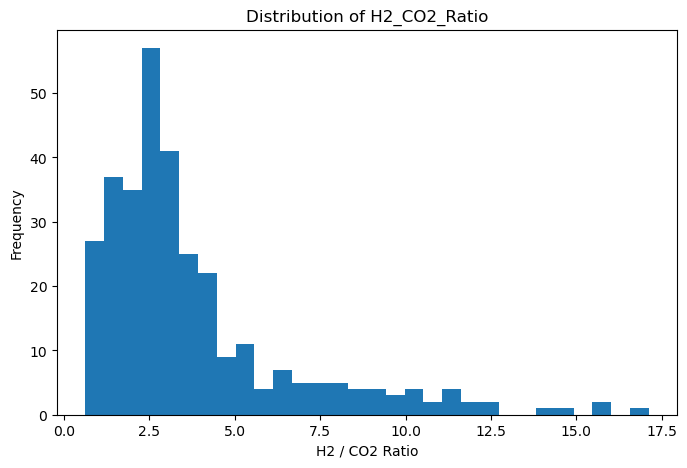

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df["H2_CO2_Ratio"], bins=30)
plt.xlabel("H2 / CO2 Ratio")
plt.ylabel("Frequency")
plt.title("Distribution of H2_CO2_Ratio")
plt.show()

In [7]:
df["H2_CO2_Ratio"].quantile([0.05, 0.25, 0.50, 0.75, 0.95])

0.05     1.011509
0.25     1.992574
0.50     2.844611
0.75     4.421451
0.95    10.305695
Name: H2_CO2_Ratio, dtype: float64

In [8]:
df[['FeedflowH2in', 'FeedflowCO2in', 'TEMPin', 'PRESout', 'TimeCost', 'Prod_MEOH']].describe()

,FeedflowH2in,FeedflowCO2in,TEMPin,PRESout,TimeCost,Prod_MEOH
count,320.000000,320.000000,320.000000,320.000000,320.000000,320.000000
mean,3.150151,1.049995,30.000407,37.498496,5.367898,0.029521
std,1.301418,0.433580,11.567508,7.229672,3.078850,0.011324
min,0.912551,0.303735,10.004390,25.027517,2.367172,0.009986
25%,2.024449,0.678012,20.043490,31.294437,3.551514,0.019946
50%,3.151425,1.049456,30.036229,37.475621,4.513274,0.028561
75%,4.272563,1.423379,39.939885,43.723250,6.026169,0.038443
max,5.397841,1.795970,49.973931,49.956616,33.293734,0.056527


In [9]:
df.isnull().sum()

FeedflowCO2in    0
FeedflowH2in     0
TEMPin           0
PRESout          0
Prod_MEOH        0
TimeCost         0
H2_CO2_Ratio     0
dtype: int64

In [10]:
X= df.drop('Prod_MEOH', axis=1)
y=df['Prod_MEOH']

In [11]:
from sklearn.model_selection import train_test_split
X_train, X_test,y_train, y_test= train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
# train the model
from sklearn.ensemble import GradientBoostingRegressor
GD_boost= GradientBoostingRegressor(random_state=42)

In [13]:
GD_boost.fit(X_train,y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [14]:
y_pred= GD_boost.predict(X_test)

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error
r2= r2_score(y_test,y_pred)
mse= mean_squared_error(y_test,y_pred)
print(f"r2_score: {r2:.6f}\nmse: {mse:.8f}")

In [29]:
import joblib

joblib.dump(GD_boost, "methanol_gbr_model.pkl")

['methanol_gbr_model.pkl']